In [1]:
import pandas as pd

df = pd.read_csv("brfss_2013_nettoye.csv")
print(df.shape)
display(df.head())

(421429, 4)


,tranche_age,imc,activite_physique,diabete
0,9.0,39.16,0.0,0
1,7.0,18.22,1.0,0
2,8.0,27.46,0.0,0
3,9.0,21.97,1.0,0
4,10.0,35.94,0.0,0


In [2]:
import pandas as pd

df = pd.read_csv("brfss_2013_nettoye.csv")
print(df.shape)
display(df.head())

(421429, 4)


,tranche_age,imc,activite_physique,diabete
0,9.0,39.16,0.0,0
1,7.0,18.22,1.0,0
2,8.0,27.46,0.0,0
3,9.0,21.97,1.0,0
4,10.0,35.94,0.0,0


,Effectif,Pourcentage (%)
Non,366093,86.87
Oui,55336,13.13


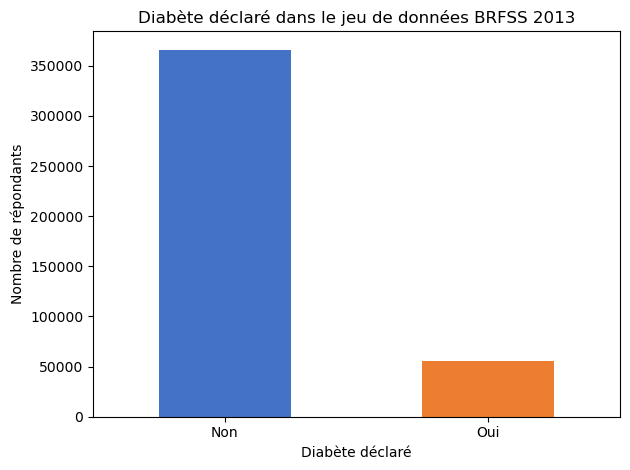

In [3]:
import matplotlib.pyplot as plt

effectifs = df["diabete"].value_counts().reindex([0, 1], fill_value=0)
effectifs.index = ["Non", "Oui"]

tableau = effectifs.to_frame("Effectif")
tableau["Pourcentage (%)"] = (effectifs / len(df) * 100).round(2)
display(tableau)

effectifs.plot.bar(color=["#4472C4", "#ED7D31"], rot=0)
plt.title("Diabète déclaré dans le jeu de données BRFSS 2013")
plt.xlabel("Diabète déclaré")
plt.ylabel("Nombre de répondants")
plt.tight_layout()
plt.show()

### Interprétation

Dans le jeu de données nettoyé, 13,13 % des répondants ont déclaré avoir reçu un diagnostic de diabète et 86,87 % ont répondu « non ». La classe « Oui » est minoritaire. Ce déséquilibre sera à prendre en compte lors de l’évaluation du modèle.

,Effectif,Diabète déclaré (%)
tranche_age,,
1,22876,1.01
2,18894,1.53
3,22528,2.54
4,23602,3.83
5,27001,6.09
6,31460,8.59
7,41083,10.93
8,46060,14.28
9,47025,17.52


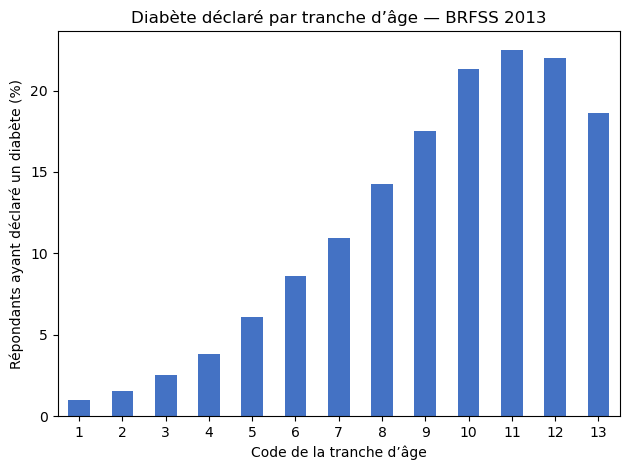

In [4]:
age = df.groupby("tranche_age")["diabete"].agg(
    Effectif="size",
    Proportion="mean"
).sort_index()

age["Diabète déclaré (%)"] = (age.pop("Proportion") * 100).round(2)
age.index = age.index.astype(int)
display(age)

age["Diabète déclaré (%)"].plot.bar(color="#4472C4", rot=0)
plt.title("Diabète déclaré par tranche d’âge — BRFSS 2013")
plt.xlabel("Code de la tranche d’âge")
plt.ylabel("Répondants ayant déclaré un diabète (%)")
plt.tight_layout()
plt.show()

,Effectif,Diabète déclaré (%)
Non,113565,19.40
Oui,307864,10.82


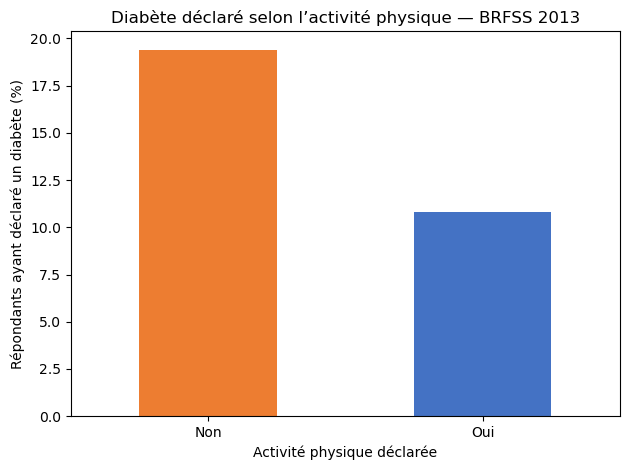

In [5]:
activite = df.groupby("activite_physique")["diabete"].agg(
    Effectif="size",
    Proportion="mean"
).reindex([0, 1])

activite.index = ["Non", "Oui"]
activite["Diabète déclaré (%)"] = (activite.pop("Proportion") * 100).round(2)
display(activite)

activite["Diabète déclaré (%)"].plot.bar(color=["#ED7D31", "#4472C4"], rot=0)
plt.title("Diabète déclaré selon l’activité physique — BRFSS 2013")
plt.xlabel("Activité physique déclarée")
plt.ylabel("Répondants ayant déclaré un diabète (%)")
plt.tight_layout()
plt.show()

### Interprétation

Dans le jeu de données nettoyé, X % des répondants qui n’ont pas déclaré d’activité physique ont déclaré un diabète, contre Y % chez ceux qui ont déclaré une activité physique. Cette comparaison montre une association entre les deux variables. Elle ne permet pas d’établir un lien de cause à effet. 

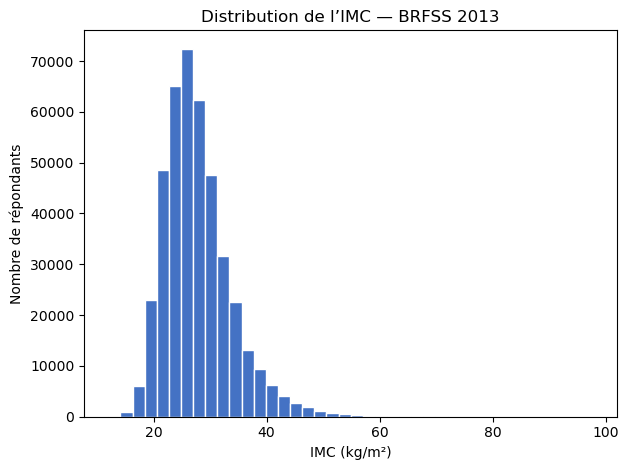

In [7]:
df["imc"].plot.hist(bins=40, color="#4472C4", edgecolor="white")

plt.title("Distribution de l’IMC — BRFSS 2013")
plt.xlabel("IMC (kg/m²)")
plt.ylabel("Nombre de répondants")
plt.tight_layout()
plt.show()

,Effectif,Moyenne,Mediane
Non,366093,27.24,26.45
Oui,55336,31.61,30.45


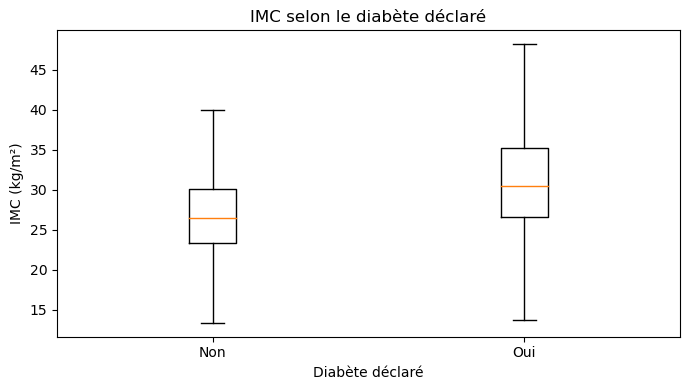

In [8]:
imc_par_groupe = df.groupby("diabete")["imc"].agg(
    Effectif="size",
    Moyenne="mean",
    Mediane="median"
).reindex([0, 1]).round(2)

imc_par_groupe.index = ["Non", "Oui"]
display(imc_par_groupe)

groupes_imc = [
    df.loc[df["diabete"] == 0, "imc"],
    df.loc[df["diabete"] == 1, "imc"]
]

plt.figure(figsize=(7, 4))
plt.boxplot(groupes_imc, showfliers=False)
plt.xticks([1, 2], ["Non", "Oui"])
plt.title("IMC selon le diabète déclaré")
plt.xlabel("Diabète déclaré")
plt.ylabel("IMC (kg/m²)")
plt.tight_layout()
plt.show()

### Conclusion de l’analyse exploratoire

- Dans le jeu de données nettoyé, 13,13 % des répondants ont déclaré un diabète.
- La proportion la plus élevée a été observée dans la tranche d’âge de code [code], avec [pourcentage] %.
- La proportion de diabète déclaré est de [X] % dans le groupe sans activité physique déclarée et de [Y] % dans le groupe avec activité physique déclarée.
- L’IMC médian est de [A] kg/m² chez les répondants ayant déclaré un diabète et de [B] kg/m² chez ceux ayant répondu « non ».

Ces comparaisons décrivent les différences observées dans le jeu de données nettoyé. Elles ne permettent pas d’établir un lien de cause à effet.